# Лабораторная работа № 3.3
**Проверка гипотезы о равенстве генеральной дисперсии заданному значению**

Исходные данные: случайная выборка значений возраста преступников л/р № 2 и результаты л/р № 1.

Взяв одну из выборок, при уровне значимости $\alpha = 0{,}05$ проверяем нулевую гипотезу $H_0: D(X) = \sigma^2$, где $\sigma^2$ — дисперсия из л/р № 1, при конкурирующих гипотезах:

а) $H_1: D(X) > \sigma^2$; б) $H_1: D(X) \ne \sigma^2$; в) $H_1: D(X) < \sigma^2$.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

In [15]:
ages = pd.read_table('../data/moscow.txt', header=None)[0]

alpha = 0.05
age_edges = [14, 23, 32, 41, 50, 59, 68, 77]
age_counts = [4811, 9476, 7243, 7951, 1140, 1472, 330]

In [16]:
def interval_variance(edges, counts):
    edges, counts = np.array(edges, float), np.array(counts, float)
    middle = (edges[:-1] + edges[1:]) / 2
    mean = np.sum(middle * counts) / counts.sum()
    return np.sum(counts * (middle - mean) ** 2) / counts.sum()

sigma2 = interval_variance(age_edges, age_counts)
print(f'σ² (л/р № 1) = {sigma2:.4f}')

σ² (л/р № 1) = 148.5362


In [17]:
def take_sample(data, size=100):
    return np.random.default_rng().choice(data, size=size, replace=False)

sample = take_sample(ages)
n = len(sample)
k = n - 1
s2 = np.var(sample, ddof=1)
chi_obs = k * s2 / sigma2

print(f'n = {n}, S² = {s2:.4f}, χ²набл = {chi_obs:.4f}')

n = 100, S² = 108.4092, χ²набл = 72.2552


In [18]:
def chi2_test(chi_obs, k, alpha, kind):
    if kind == 'right':
        crit = (chi2.ppf(1 - alpha, k),)
        reject = chi_obs > crit[0]
    elif kind == 'two':
        crit = (chi2.ppf(alpha / 2, k), chi2.ppf(1 - alpha / 2, k))
        reject = chi_obs < crit[0] or chi_obs > crit[1]
    else:
        crit = (chi2.ppf(alpha, k),)
        reject = chi_obs < crit[0]
    return crit, reject


cases = {'а) H1: D(X) > σ²': 'right',
         'б) H1: D(X) ≠ σ²': 'two',
         'в) H1: D(X) < σ²': 'left'}

results = {}
for title, kind in cases.items():
    crit, reject = chi2_test(chi_obs, k, alpha, kind)
    results[title] = (kind, crit)
    crit_str = ' и '.join(f'{c:.4f}' for c in crit)
    print(f'{title}: χ²кр = {crit_str} → H0 {"отвергается" if reject else "не отвергается"}')

а) H1: D(X) > σ²: χ²кр = 123.2252 → H0 не отвергается
б) H1: D(X) ≠ σ²: χ²кр = 73.3611 и 128.4220 → H0 отвергается
в) H1: D(X) < σ²: χ²кр = 77.0463 → H0 отвергается


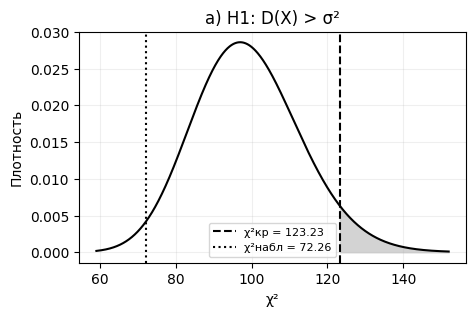

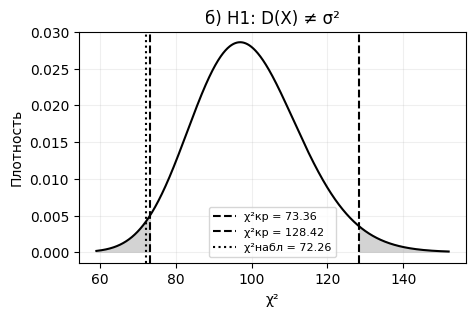

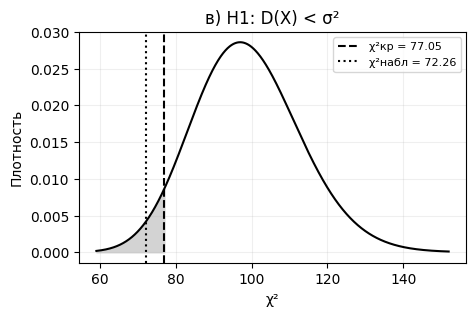

In [19]:
def plot_test(chi_obs, k, title, kind, crit):
    x = np.linspace(max(0.01, min(chi2.ppf(0.0005, k), chi_obs * 0.9)),
                    max(chi2.ppf(0.9995, k), chi_obs * 1.1), 1500)
    y = chi2.pdf(x, k)
    if kind == 'right':
        area = x > crit[0]
    elif kind == 'two':
        area = (x < crit[0]) | (x > crit[1])
    else:
        area = x < crit[0]
    plt.figure(figsize=(5, 3))
    plt.plot(x, y, color='black')
    plt.fill_between(x, y, where=area, color='lightgray')
    for c in crit:
        plt.axvline(c, color='black', linestyle='--', label=f'χ²кр = {c:.2f}')
    plt.axvline(chi_obs, color='black', linestyle=':', label=f'χ²набл = {chi_obs:.2f}')
    plt.title(title)
    plt.xlabel('χ²')
    plt.ylabel('Плотность')
    plt.grid(alpha=0.2)
    plt.legend(fontsize=8)
    plt.show()


for title, (kind, crit) in results.items():
    plot_test(chi_obs, k, title, kind, crit)